In [1]:
import sys
!{sys.executable} -m pip install scikit-learn


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip


In [2]:
import sklearn
print(sklearn.__version__)

1.9.0


In [3]:
import os
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torchvision

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("train_dataframe.csv")

print(df.head())
print("\nShape:", df.shape)

                         image_path  spoof_type  illumination  environment  \
0   Data/train/2623/live/000000.jpg           0             0            0   
1  Data/train/5489/spoof/000001.jpg           6             1            1   
2  Data/train/7149/spoof/000002.jpg           7             1            1   
3  Data/train/4980/spoof/000003.jpg           5             1            2   
4  Data/train/7124/spoof/000004.jpg           7             4            2   

   live_spoof  
0           0  
1           1  
2           1  
3           1  
4           1  

Shape: (494405, 5)


In [5]:
print(df.columns)

Index(['image_path', 'spoof_type', 'illumination', 'environment',
       'live_spoof'],
      dtype='str')


In [6]:
print("Unique Spoof Types:")
print(sorted(df["spoof_type"].unique()))

Unique Spoof Types:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]


In [7]:
print(df["spoof_type"].value_counts().sort_index())

spoof_type
0     162462
1      35547
2      31221
3      31776
4      33647
5      30167
6      33285
7      31072
8      33085
9      31527
10     40616
Name: count, dtype: int64


In [8]:
train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["spoof_type"]
)

print("Training Images :", len(train_df))
print("Validation Images :", len(val_df))

Training Images : 395524
Validation Images : 98881


In [9]:
train_df.to_csv("train_split.csv", index=False)
val_df.to_csv("val_split.csv", index=False)

print("Train and Validation CSV files saved successfully!")

Train and Validation CSV files saved successfully!


In [10]:
class CelebASpoofDataset(Dataset):

    def __init__(self, dataframe, root_dir, transform=None):
        self.dataframe = dataframe
        self.root_dir = root_dir
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        image_path = os.path.join(
            self.root_dir,
            self.dataframe.iloc[idx]["image_path"]
        )

        image = Image.open(image_path).convert("RGB")

        label = int(self.dataframe.iloc[idx]["spoof_type"])

        if self.transform:
            image = self.transform(image)

        return image, label

In [11]:
train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

print("Transforms Created Successfully!")

Transforms Created Successfully!


In [12]:
DATASET_ROOT = "CelebA_Spoof_/CelebA_Spoof"

train_dataset = CelebASpoofDataset(
    train_df,
    DATASET_ROOT,
    train_transform
)

val_dataset = CelebASpoofDataset(
    val_df,
    DATASET_ROOT,
    val_transform
)

print("Train Dataset :", len(train_dataset))
print("Validation Dataset :", len(val_dataset))

Train Dataset : 395524
Validation Dataset : 98881


In [13]:
image, label = train_dataset[0]

print(image.shape)
print(label)

torch.Size([3, 224, 224])
3


In [14]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=4,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

print("Train Batches :", len(train_loader))
print("Validation Batches :", len(val_loader))

Train Batches : 12361
Validation Batches : 3091


In [15]:
images, labels = next(iter(train_loader))

print("Images Shape :", images.shape)
print("Labels Shape :", labels.shape)
print("First 10 Labels :", labels[:10])

Images Shape : torch.Size([32, 3, 224, 224])
Labels Shape : torch.Size([32])
First 10 Labels : tensor([2, 8, 4, 9, 0, 8, 3, 0, 0, 4])


In [16]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(device)

cuda


In [17]:
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

print("EfficientNet-B0 loaded successfully!")

EfficientNet-B0 loaded successfully!


In [18]:
model.classifier[1] = torch.nn.Linear(
    model.classifier[1].in_features,
    11
)

model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=11, bias=True)
)


In [19]:
dummy = torch.randn(1, 3, 224, 224).to(device)

output = model(dummy)

print(output.shape)

torch.Size([1, 11])


In [20]:
criterion = torch.nn.CrossEntropyLoss()

print("Loss Function Ready!")

Loss Function Ready!


In [21]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

print("Optimizer Ready!")

Optimizer Ready!


In [22]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

print("Scheduler Ready!")

Scheduler Ready!


In [23]:
EPOCHS = 20

best_val_accuracy = 0.0

train_loss_history = []
val_loss_history = []

train_acc_history = []
val_acc_history = []

In [24]:
class_names = {
    0: "Live",
    1: "Photo",
    2: "Poster",
    3: "A4",
    4: "Face Mask",
    5: "Upper Body Mask",
    6: "Region Mask",
    7: "PC",
    8: "Pad",
    9: "Phone",
    10: "3D Mask"
}

In [25]:
import torch

print(torch.cuda.get_device_name(0))

NVIDIA H200 NVL


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.4482791].


Image Shape: torch.Size([3, 224, 224])
Label: 3


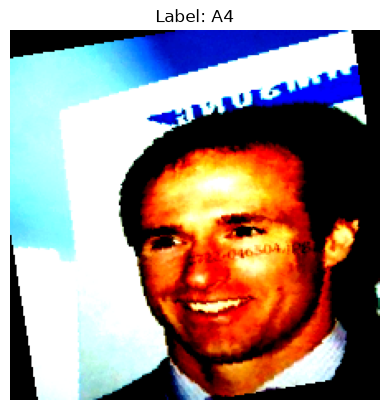

In [26]:
import matplotlib.pyplot as plt

image, label = train_dataset[0]

print("Image Shape:", image.shape)
print("Label:", label)

plt.imshow(image.permute(1,2,0))
plt.title(f"Label: {class_names[label]}")
plt.axis("off")
plt.show()

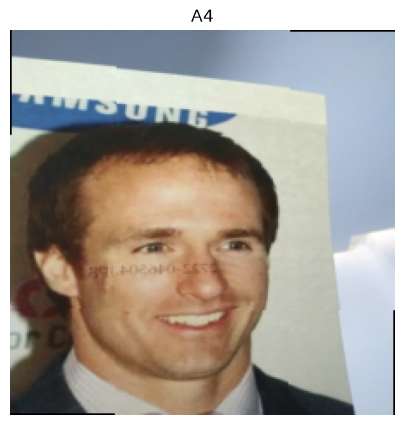

In [29]:
import matplotlib.pyplot as plt
import torch

image, label = train_dataset[0]

# Undo normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

image_display = image * std + mean
image_display = image_display.clamp(0,1)

plt.figure(figsize=(5,5))
plt.imshow(image_display.permute(1,2,0))
plt.title(class_names[label])
plt.axis("off")
plt.show()

In [30]:
!pip install opencv-python-headless

Defaulting to user installation because normal site-packages is not writeable


In [31]:
print("Training Dataset :", len(train_dataset))
print("Validation Dataset :", len(val_dataset))

Training Dataset : 395524
Validation Dataset : 98881


In [32]:
images, labels = next(iter(train_loader))

print("Images Shape :", images.shape)
print("Labels Shape :", labels.shape)

Images Shape : torch.Size([32, 3, 224, 224])
Labels Shape : torch.Size([32])


In [33]:
print(labels)

tensor([ 9,  5, 10,  0,  0,  4,  7,  1,  0, 10,  6,  1,  4,  5,  5,  0,  3,  0,
         1, 10, 10,  7, 10,  0,  6,  0,  8,  1,  0, 10,  5,  1])


In [34]:
images = images.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Output Shape:", outputs.shape)

Output Shape: torch.Size([32, 11])


In [35]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Total Parameters: {total_params:,}")
print(f"Trainable Parameters: {trainable_params:,}")

Total Parameters: 4,021,639
Trainable Parameters: 4,021,639


In [36]:
%pip install opencv-python


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [37]:
import cv2
print(cv2.__version__)

5.0.0


In [38]:
print(df.iloc[0]["image_path"])

Data/train/2623/live/000000.jpg


In [39]:
import os

print(os.getcwd())

/srv/data/datasets/Face-Anti-Spoofing


In [40]:
import os

for root, dirs, files in os.walk(".", topdown=True):
    if "000000.jpg" in files:
        print(root)
        break

./CelebA_Spoof_/CelebA_Spoof/Data/train/2623/live


In [ ]:
print(df.iloc[0]["image_path"])

In [ ]:
import os
print(os.getcwd())

In [ ]:
import os
print(os.path.exists(df.iloc[0]["image_path"]))

In [44]:
with open("004046_BB.txt", "r") as f:
    for _ in range(5):
        print(f.readline().strip())

58.617077 60.623283 58.884838 68.484187 0.991446






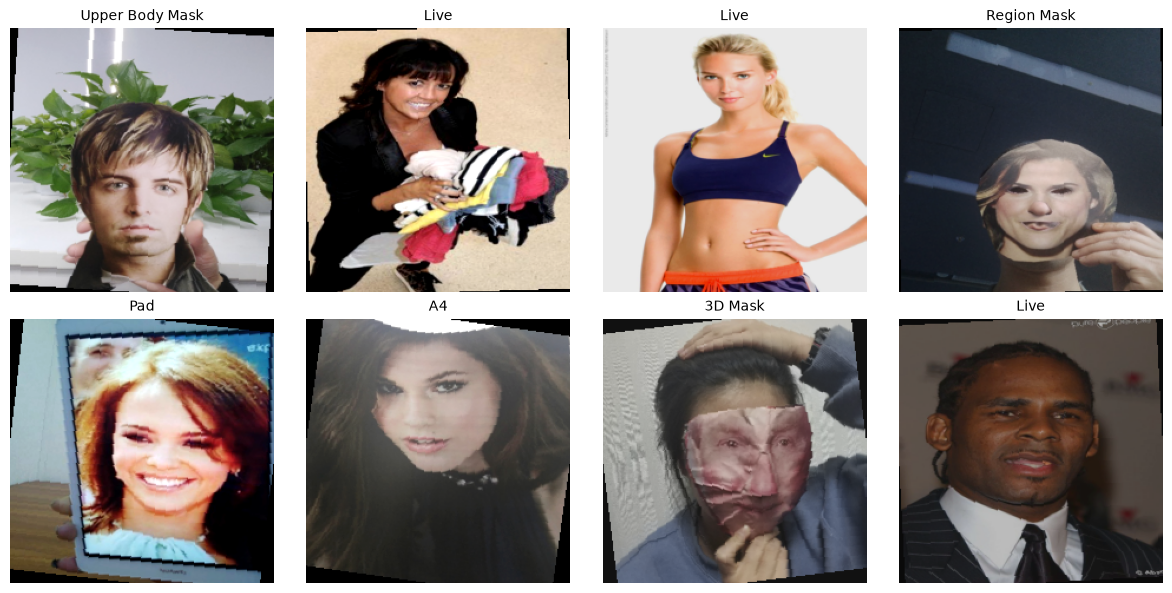

In [45]:
import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    img = images[i]

    # Undo normalization
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

    img = img * std + mean
    img = img.clamp(0,1)

    ax.imshow(img.permute(1,2,0))
    ax.set_title(class_names[int(labels[i])], fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [46]:
pip install mediapipe opencv-python tqdm


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [47]:
base_path = "CelebA_Spoof_/CelebA_Spoof"

image_path = os.path.join(base_path, df.iloc[0]["image_path"])

print(image_path)
print(os.path.exists(image_path))

CelebA_Spoof_/CelebA_Spoof/Data/train/2623/live/000000.jpg
True


In [48]:
images, labels = next(iter(train_loader))

print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [49]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load pretrained EfficientNet-B0
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

# Replace classifier
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    11      # Change if your number of classes is different
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=11, bias=True)
)


In [50]:
criterion = nn.CrossEntropyLoss()

In [51]:
import torch.optim as optim

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

In [52]:
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [53]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA H200 NVL


In [54]:
print(sorted(train_df["spoof_type"].unique()))
print(train_df["spoof_type"].nunique())

[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
11


In [55]:
EPOCHS = 25

best_acc = 0.0

train_losses = []
val_losses = []

train_accs = []
val_accs = []

In [56]:
from tqdm import tqdm
import torch

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    pbar = tqdm(loader)

    for images, labels in pbar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

        pbar.set_description(
            f"Loss:{loss.item():.4f}"
        )

    epoch_loss = running_loss / len(loader)

    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [57]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0

    correct = 0

    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [58]:
EPOCHS = 25

best_acc = 0.0

train_losses = []
val_losses = []

train_accs = []
val_accs = []

In [61]:
save_path = "efficientnet_b0_best.pth"

best_acc = 0.0

for epoch in range(EPOCHS):

    print(f"\nEpoch {epoch+1}/{EPOCHS}")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion
    )

    scheduler.step(val_acc)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.2f}%")
    print(f"Validation Loss : {val_loss:.4f}")
    print(f"Validation Accuracy : {val_acc:.2f}%")

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), save_path)
        print("✅ Best model saved!")

print("\nTraining Completed!")
print(f"Best Validation Accuracy : {best_acc:.2f}%")


Epoch 1/25


Loss:2.3764: 100%|██████████| 12361/12361 [22:09<00:00,  9.30it/s]


Train Loss : 0.1483
Train Accuracy : 94.86%
Validation Loss : 0.0329
Validation Accuracy : 98.84%
✅ Best model saved!

Epoch 2/25


Loss:0.0137: 100%|██████████| 12361/12361 [22:00<00:00,  9.36it/s]


Train Loss : 0.0451
Train Accuracy : 98.43%
Validation Loss : 0.0155
Validation Accuracy : 99.47%
✅ Best model saved!

Epoch 3/25


...

Train Loss : 0.0011
Train Accuracy : 99.96%
Validation Loss : 0.0035
Validation Accuracy : 99.93%
✅ Best model saved!

Epoch 21/25


Loss:0.0000:   6%|▋         | 776/12361 [01:25<08:46, 22.01it/s]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

Loss:0.0058: 100%|██████████| 12361/12361 [22:14<00:00,  9.26it/s]


Train Loss : 0.0009
Train Accuracy : 99.97%
Validation Loss : 0.0100
Validation Accuracy : 99.87%

Epoch 25/25


Loss:3.5527: 100%|██████████| 12361/12361 [22:23<00:00,  9.20it/s]


Train Loss : 0.0011
Train Accuracy : 99.97%
Validation Loss : 0.0147
Validation Accuracy : 99.84%

Training Completed!
Best Validation Accuracy : 99.94%
